# CS-13410 Introduction to Machine Learning: Semester Project
## Part 1: Data Understanding, Preprocessing & Leakage-Free Pipeline

**Group Members:** (Muhammad Abdullah Noor - 70146205), (Mehrab Fiaz - 70148905), (Muhammad Ahmed - 70149644)

**GitHub Repository:** https://github.com/AbdullahDev-git/hotel-booking-cancellation-prediction

**Dataset:** Hotel Booking Demand (booking cancellation prediction)


---
**Contents**
1. Problem Framing
2. Loading the Data & First Look
3. Exploratory Data Analysis (EDA)
4. Data Cleaning (including removal of target-leakage columns)
5. Outlier Analysis
6. Train/Test Split
7. Feature Construction
8. Leakage-Free Preprocessing Pipeline
9. Proof that the Pipeline is Leakage-Free
10. Handling Class Imbalance
11. Summary & Plan for Next Parts

## 1. Problem Framing

| Item | Description |
|---|---|
| **Business problem** | Hotels lose money when a booked room is cancelled and ends up empty. If a hotel can predict **at booking time** which reservations are likely to be cancelled, it can manage overbooking, ask for deposits, or contact risky guests. |
| **Prediction target** | `is_canceled` (1 = booking was cancelled, 0 = guest stayed) |
| **Task type** | **Binary classification** |
| **Success metric** | **F1-score** and **ROC-AUC** (primary), with **Recall** for the cancelled class as a secondary metric (missing a likely cancellation is the costly mistake). |
| **Why not accuracy?** | After cleaning, only about 27.5% of bookings are cancelled. A model that always says "not cancelled" would score ~72.5% accuracy while finding no cancellations at all. |

**Why this dataset is suitable**
- **87,000+ unique bookings** after cleaning (far above the 1,000-row minimum) with 29 usable features: numeric (`lead_time`, `adr`, `adults`...) and categorical (`hotel`, `country`, `market_segment`, `deposit_type`...).
- It has **real data problems**, so every preprocessing step in the brief is needed: missing values (including a column that is 94% empty), about 32,000 duplicate rows, extreme values (a room price of 5,400), zero-inflated count columns, and class imbalance.
- It contains a **target-leakage trap**: the column `reservation_status` literally contains the answer (`Canceled`/`No-Show`/`Check-Out`). This is a perfect, real example for the "leakage-free" theme of Part 1 (see Section 4).
- Enough structure for later parts: tree models and ensembles (Parts 2-3), a neural network and clustering/PCA (Part 4).
- Supports a **fairness and responsible-use discussion** in Part 4: `country` (nationality) is a strong predictor, and using it to treat guests differently could be discriminatory.

**Data source:** Antonio, de Almeida & Nunes (2019), *Hotel booking demand datasets*, Data in Brief 22, 41-49. Real bookings from two hotels in Portugal (a resort hotel and a city hotel), arrivals between 2015 and 2017. The author's data is released openly (CC BY 4.0) and contains no names or contact details, so there are no privacy or licensing issues.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

# ---- CONFIGURATION ----
DATA_PATH = "hotel_bookings.csv"
TARGET = "is_canceled"
RANDOM_STATE = 42

## 2. Loading the Data & First Look

In [2]:
df = pd.read_csv(DATA_PATH)
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
print("Duplicate rows:", df.duplicated().sum(), "(%.1f%% of the data)" % (100 * df.duplicated().mean()))
print()
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

Duplicate rows: 31994 (26.8% of the data)



,count,mean,std,min,50%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.000,1.0
lead_time,119390.0,104.011416,106.863097,0.00,69.000,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.000,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,28.000,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,16.000,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,1.000,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,2.000,50.0
adults,119390.0,1.856403,0.579261,0.00,2.000,55.0
children,119386.0,0.103890,0.398561,0.00,0.000,10.0
babies,119390.0,0.007949,0.097436,0.00,0.000,10.0


In [5]:
# Missing values 
miss = df.isna().sum()
miss = miss[miss > 0].to_frame("missing")
miss["percent"] = (miss["missing"] / len(df) * 100).round(2)
miss

,missing,percent
children,4,0.00
country,488,0.41
agent,16340,13.69
company,112593,94.31


**Observations**
- `company` is **94% missing**, `agent` is about 14% missing, `country` and `children` have a handful of missing values.
- **27% of the rows are exact duplicates** (31,994 rows). There is no booking ID, so identical rows cannot be told apart.
- The target `is_canceled` is cancelled in about 37% of the raw rows (this changes once duplicates are removed, see below).
- `adr` (average daily rate = room price per night) has a **minimum below 0 and a maximum of 5,400**, and some bookings have 55 adults or 0 guests. These look like data errors or extreme values.
- Columns `reservation_status` and `reservation_status_date` look suspicious: they describe what happened *after* the booking. We will examine them in Section 4.

## 3. Exploratory Data Analysis (EDA)
EDA is done only to *understand* the data. We use a **de-duplicated copy** (`eda_df`) so duplicate rows do not distort the percentages. No statistic from this section is used to fit any transformation, so there is no leakage.

In [6]:
eda_df = df.drop_duplicates().copy()
eda_df["status"] = eda_df[TARGET].map({0: "Not canceled", 1: "Canceled"})
print("Rows used for EDA:", len(eda_df))

Rows used for EDA: 87396


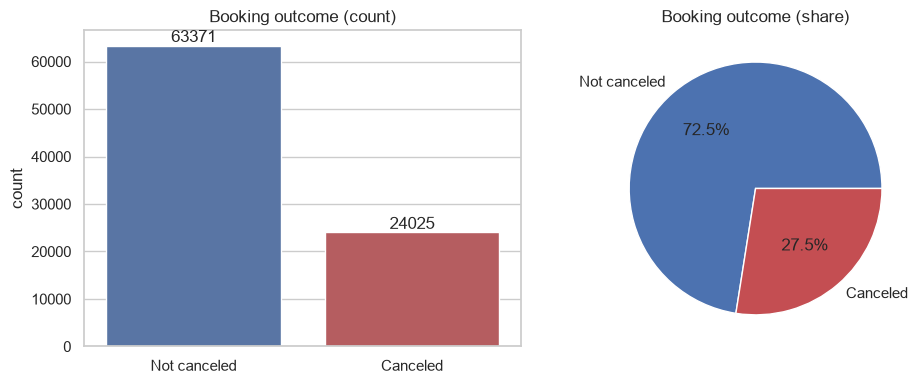

In [7]:
# Visualisation 1: Target distribution (class imbalance)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
counts = eda_df["status"].value_counts()[["Not canceled", "Canceled"]]
sns.countplot(x="status", data=eda_df, ax=ax[0], order=["Not canceled", "Canceled"], palette=["#4C72B0", "#C44E52"])
ax[0].set_title("Booking outcome (count)"); ax[0].set_xlabel("")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")
ax[1].pie(counts, labels=counts.index, autopct="%1.1f%%", colors=["#4C72B0", "#C44E52"])
ax[1].set_title("Booking outcome (share)")
plt.tight_layout(); plt.show()

**Insight:** about 27.5% of unique bookings are cancelled, so the dataset is **imbalanced** (roughly 2.6 : 1). We must handle this (Section 10) and use metrics other than plain accuracy.

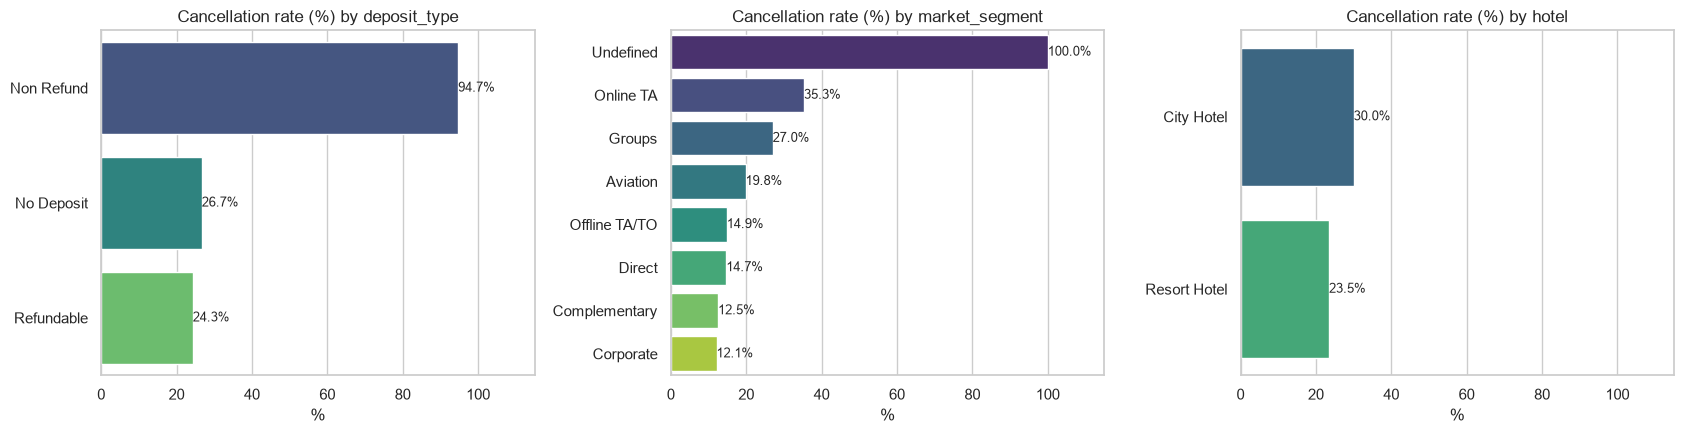

In [8]:
# Visualisation 2: Cancellation rate by deposit type, market segment and hotel
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for a, col in zip(ax, ["deposit_type", "market_segment", "hotel"]):
    rate = eda_df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=a, palette="viridis")
    a.set_title(f"Cancellation rate (%) by {col}"); a.set_xlabel("%"); a.set_ylabel("")
    for p in a.patches:
        a.annotate(f"{p.get_width():.1f}%", (p.get_width(), p.get_y()+p.get_height()/2), va="center", ha="left", fontsize=9)
    a.set_xlim(0, 115)
plt.tight_layout(); plt.show()

**Insight:**
- Bookings made through **Online Travel Agents** are cancelled far more often than Direct or Corporate bookings. City hotel bookings are cancelled more than resort bookings.
- Surprisingly, **"Non Refund" deposits have about a 95% cancellation rate**, although you would expect the opposite. These are only about 1% of the rows and probably reflect how the hotels recorded certain bookings (a data artefact). We note it as a **warning for interpretation**: a model may learn this pattern without it being a true cause.

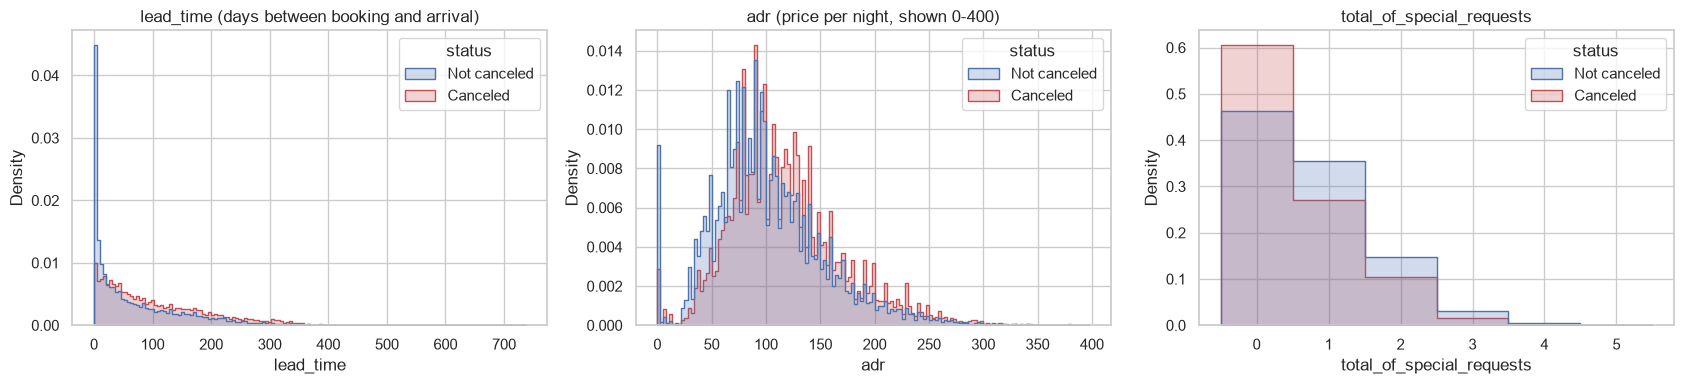

In [9]:
# Visualisation 3: Lead time, price (adr) and special requests by outcome
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=eda_df, x="lead_time", hue="status", element="step", stat="density", common_norm=False,
             hue_order=["Not canceled", "Canceled"], palette=["#4C72B0", "#C44E52"], ax=ax[0])
ax[0].set_title("lead_time (days between booking and arrival)")

sns.histplot(data=eda_df[(eda_df.adr >= 0) & (eda_df.adr <= 400)], x="adr", hue="status", element="step",
             stat="density", common_norm=False, hue_order=["Not canceled", "Canceled"],
             palette=["#4C72B0", "#C44E52"], ax=ax[1])
ax[1].set_title("adr (price per night, shown 0-400)")

sns.histplot(data=eda_df, x="total_of_special_requests", hue="status", discrete=True, element="step", stat="density",
             common_norm=False, hue_order=["Not canceled", "Canceled"], palette=["#4C72B0", "#C44E52"], ax=ax[2])
ax[2].set_title("total_of_special_requests")
plt.tight_layout(); plt.show()

**Insight:** cancelled bookings were made **much earlier** (longer lead time), are slightly more expensive, and have **fewer special requests**. A guest who asks for special services is more committed to coming.

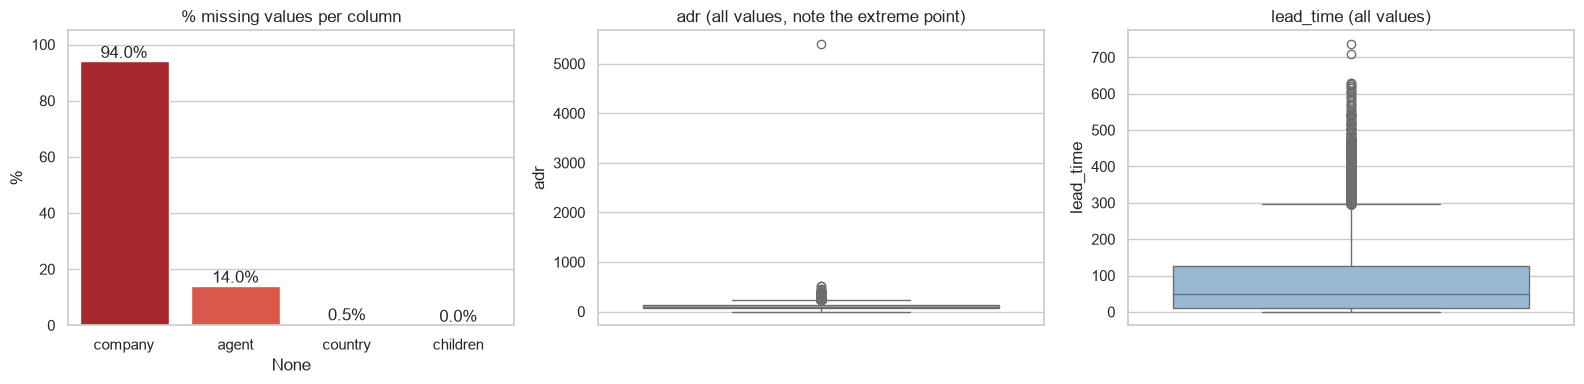

Max adr: 5400.0 | Min adr: -6.38


In [10]:
# Visualisation 4: Data quality: missing values and the extreme price outlier
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
miss_pct = (eda_df.isna().mean() * 100)
miss_pct = miss_pct[miss_pct > 0].sort_values(ascending=False)
sns.barplot(x=miss_pct.index, y=miss_pct.values, ax=ax[0], palette="Reds_r")
ax[0].set_title("% missing values per column"); ax[0].set_ylabel("%"); ax[0].set_ylim(0, 105)
for p in ax[0].patches:
    ax[0].annotate(f"{p.get_height():.1f}%", (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

sns.boxplot(y=eda_df["adr"], ax=ax[1], color="#8FB8DE")
ax[1].set_title("adr (all values, note the extreme point)")

sns.boxplot(y=eda_df["lead_time"], ax=ax[2], color="#8FB8DE")
ax[2].set_title("lead_time (all values)")
plt.tight_layout(); plt.show()
print("Max adr:", eda_df["adr"].max(), "| Min adr:", eda_df["adr"].min())

**Insight:** `company` is almost entirely empty and will be dropped. A single room price of 5,400 per night stretches the whole `adr` boxplot, so extreme values must be handled before scaling.

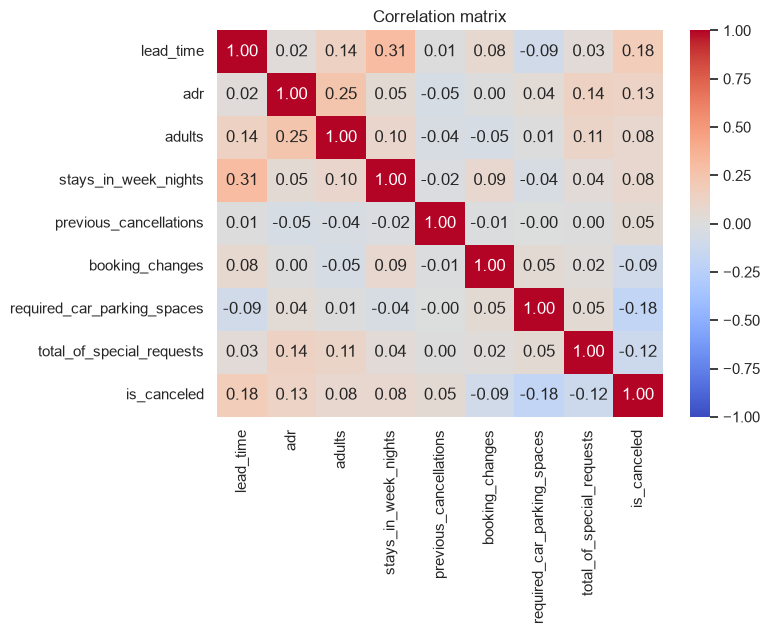

In [11]:
# Visualisation 5: Correlation heatmap of numeric features (+ cancellation as 0/1)
corr_cols = ["lead_time", "adr", "adults", "stays_in_week_nights", "previous_cancellations",
             "booking_changes", "required_car_parking_spaces", "total_of_special_requests", TARGET]
plt.figure(figsize=(8, 6.5))
sns.heatmap(eda_df[corr_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Correlation matrix")
plt.tight_layout(); plt.show()

**Insight:** `lead_time` has the strongest positive correlation with cancellation (about 0.18), while `required_car_parking_spaces` (about -0.18), `total_of_special_requests` and `booking_changes` are negatively correlated. Correlations are modest overall, so no single numeric feature predicts cancellation on its own.

## 4. Data Cleaning

Steps in this section only apply **fixed rules** (remove duplicates, drop columns that cannot be used, fix types). They do not learn any statistic from the data (no means, medians, etc.), so doing them before the train/test split causes **no leakage**. Anything that *learns* from data (imputation values, scaling, encoding categories) is done later inside the pipeline.

In [12]:
# 4.1 Remove exact duplicate rows (done BEFORE dropping any column, so rows are compared on all original information).
# Why before the split? If the same row appeared in both train and test, the model would be "tested"
# on something it already saw, which is a form of leakage.
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows remain")
print("Cancellation rate after removing duplicates: %.3f" % df[TARGET].mean())

Removed 31994 duplicate rows -> 87396 rows remain
Cancellation rate after removing duplicates: 0.275


In [13]:
# 4.2 Remove impossible bookings: no guests at all (adults + children + babies = 0)
no_guests = (df["adults"] + df["children"].fillna(0) + df["babies"]) == 0
print("Bookings with zero guests:", no_guests.sum())
df = df[~no_guests].reset_index(drop=True)
print("Rows remaining:", len(df))

Bookings with zero guests: 166
Rows remaining: 87230


### 4.3 Target leakage: the most important cleaning step

Some columns describe what happened **after** the booking, or are only known **after** the guest arrives. At the moment we want to make a prediction (when the booking is made) these columns do not exist, so using them would be cheating. This is called **target leakage**.

In [14]:
print(pd.crosstab(df["reservation_status"], df[TARGET], margins=True))

is_canceled             0      1    All
reservation_status                     
Canceled                0  22996  22996
Check-Out           63221      0  63221
No-Show                 0   1013   1013
All                 63221  24009  87230


The table shows that `reservation_status` is a perfect copy of the target: `Canceled` and `No-Show` always mean `is_canceled = 1`, and `Check-Out` always means 0. A model using it would get ~100% accuracy and be completely useless in real life.

| Column | Why it is removed |
|---|---|
| `reservation_status` | Contains the answer (the outcome of the booking). |
| `reservation_status_date` | The date the status changed (the cancellation date or check-out date), so it is known only after the outcome. |
| `assigned_room_type` | The room actually given at check-in. It is assigned after the booking, so it is not known when we predict. (`reserved_room_type` is kept because it is chosen at booking time.) |
| `company` | 94% missing. There is too little information to impute. |
| `arrival_date_year`, `arrival_date_week_number`, `arrival_date_day_of_month` | The year (2015-2017) would tie the model to those years and not generalise to future ones. Week number is redundant with the month, and day of month carries little meaning. We keep `arrival_date_month` to capture seasonality. |

> **Two different kinds of leakage:** (1) **Target leakage**: using columns that would not be known at prediction time (handled here). (2) **Preprocessing leakage**: letting test-set statistics influence scaling/imputation (handled by the Pipeline in Section 8).

In [15]:
# 4.4 Convert agent ID (a number used as a label) into a categorical label, keeping missing as NaN
df["agent"] = ("agent_" + df["agent"].astype("Int64").astype(str)).where(df["agent"].notna())

# 4.5 Separate target and features
LEAKAGE_AND_DROP = ["reservation_status", "reservation_status_date", "assigned_room_type", "company",
                    "arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month"]
y = df[TARGET].astype(int)
X = df.drop(columns=[TARGET] + LEAKAGE_AND_DROP)

print("X shape:", X.shape, "| y shape:", y.shape)
print("Share cancelled: %.3f" % y.mean())
print("\nMissing values left in X (will be imputed inside the pipeline):")
print(X.isna().sum()[X.isna().sum() > 0])
X.head()

X shape: (87230, 24) | y shape: (87230,)
Share cancelled: 0.275

Missing values left in X (will be imputed inside the pipeline):


children        4
country       447
agent       12141
dtype: int64


,hotel,lead_time,arrival_date_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,agent,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests
0,Resort Hotel,342,July,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,3,No Deposit,NaN,0,Transient,0.0,0,0
1,Resort Hotel,737,July,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,4,No Deposit,NaN,0,Transient,0.0,0,0
2,Resort Hotel,7,July,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,0,No Deposit,NaN,0,Transient,75.0,0,0
3,Resort Hotel,13,July,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,0,No Deposit,agent_304,0,Transient,75.0,0,0
4,Resort Hotel,14,July,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,0,No Deposit,agent_240,0,Transient,98.0,0,1


## 5. Outlier Analysis

In [16]:
# IQR rule: a value is an outlier if it lies outside [Q1 - 1.5*IQR, Q3 + 1.5*IQR]
rows = []
for col in ["lead_time", "adr", "adults", "stays_in_week_nights", "booking_changes", "days_in_waiting_list"]:
    q1, q3 = X[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((X[col] < lo) | (X[col] > hi)).sum())
    rows.append([col, q1, q3, round(lo, 1), round(hi, 1), X[col].min(), X[col].max(), n_out, round(100 * n_out / len(X), 1)])
pd.DataFrame(rows, columns=["Feature", "Q1", "Q3", "Lower bound", "Upper bound", "Min", "Max", "# outliers", "% of rows"])

,Feature,Q1,Q3,Lower bound,Upper bound,Min,Max,# outliers,% of rows
0,lead_time,11.00,125.0,-160.0,296.0,0.00,737.0,2394,2.7
1,adr,72.25,134.1,-20.5,226.9,-6.38,5400.0,2508,2.9
2,adults,2.00,2.0,2.0,2.0,0.00,55.0,22733,26.1
3,stays_in_week_nights,1.00,4.0,-3.5,8.5,0.00,50.0,1514,1.7
4,booking_changes,0.00,0.0,0.0,0.0,0.00,18.0,15805,18.1
5,days_in_waiting_list,0.00,0.0,0.0,0.0,0.00,391.0,855,1.0


**Findings**
- `lead_time` and `adr` have **genuine extreme values** (for example a price of 5,400 per night, or a booking made 737 days ahead). These are rare but real and would distort scaling.
- `stays_in_week_nights` has only a small share of outliers (long stays of up to 50 nights, which are rare but possible).
- For `adults`, `booking_changes` and `days_in_waiting_list` the IQR is zero (Q1 = Q3, because most rows have the same value, 2 adults or 0), so the IQR rule flags a large share of rows (26% for `adults`, 18% for `booking_changes`). That is the rule being too strict for concentrated or zero-inflated columns, not necessarily bad data.

**Decisions**
1. For continuous or wide-ranging columns (`lead_time`, `adr`, `adults`, nights, totals): **cap at the 1st / 99th percentile** (winsorising) inside the pipeline. This limits extreme values without deleting rows.
2. For **zero-inflated count columns** (`days_in_waiting_list`, `previous_cancellations`, `previous_bookings_not_canceled`, `booking_changes`, `required_car_parking_spaces`, `children`, `babies`): apply a **log transform** `log(1 + x)`. Capping would be harmful here (for example the 99th percentile of `babies` is 0, which would erase the column).
3. Percentile bounds are learned from the **training data only**, so this is leakage-free.

## 6. Train / Test Split
We split **before** any learned preprocessing. The test set is kept aside and treated as unseen future data. We use `stratify=y` so both sets keep the same share of cancellations.

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nShare cancelled (train): %.3f" % y_train.mean())
print("Share cancelled (test) : %.3f" % y_test.mean())

Train: (69784, 24) | Test: (17446, 24)

Share cancelled (train): 0.275
Share cancelled (test) : 0.275


## 7. Feature Construction

We create new features from existing ones. These transformations work **row by row** (no statistics learned from other rows), so they are safe. They are wrapped in a `FunctionTransformer` so they run automatically inside the pipeline.

| New feature | Idea |
|---|---|
| `total_nights` | Weekend nights + week nights: the total length of the stay. |
| `total_guests` | Adults + children + babies: the size of the party. |
| `has_children` | 1 if the booking includes children or babies (families behave differently from couples or business travellers). |
| `has_prev_cancel` | 1 if the guest has cancelled before. Past behaviour is a strong signal. |
| `lead_time_group` | Buckets lead time into 0-7, 8-30, 31-90, 91-180 and 181+ days, because the effect of lead time is not a straight line. |

In [18]:
def add_features(data):
    data = data.copy()
    data["total_nights"] = data["stays_in_weekend_nights"] + data["stays_in_week_nights"]
    data["total_guests"] = data["adults"] + data["children"] + data["babies"]     # NaN if children is missing (imputed later)
    data["has_children"] = ((data["children"] > 0) | (data["babies"] > 0)).astype(int)
    data["has_prev_cancel"] = (data["previous_cancellations"] > 0).astype(int)
    data["lead_time_group"] = pd.cut(
        data["lead_time"], bins=[-1, 7, 30, 90, 180, np.inf],
        labels=["0-7", "8-30", "31-90", "91-180", "181+"]
    ).astype(str)
    return data

feature_builder = FunctionTransformer(add_features, validate=False)

# Column groups (only names are used here, no statistics are learned)
cap_cols    = ["lead_time", "adr", "adults", "stays_in_weekend_nights", "stays_in_week_nights",
               "total_of_special_requests", "total_nights", "total_guests"]          # capping + scaling
skew_cols   = ["days_in_waiting_list", "previous_cancellations", "previous_bookings_not_canceled",
               "booking_changes", "required_car_parking_spaces", "children", "babies"]  # log transform + scaling
binary_cols = ["is_repeated_guest", "has_prev_cancel", "has_children"]                # already 0/1
cat_cols    = ["hotel", "arrival_date_month", "meal", "country", "market_segment", "distribution_channel",
               "reserved_room_type", "deposit_type", "agent", "customer_type", "lead_time_group"]

X_peek = add_features(X_train)
assert set(cap_cols + skew_cols + binary_cols + cat_cols) == set(X_peek.columns), "column groups do not match"
print("Capping+scaling  (%d):" % len(cap_cols), cap_cols)
print("Log+scaling      (%d):" % len(skew_cols), skew_cols)
print("Binary (as is)   (%d):" % len(binary_cols), binary_cols)
print("Categorical      (%d):" % len(cat_cols), cat_cols)

Capping+scaling  (8): ['lead_time', 'adr', 'adults', 'stays_in_weekend_nights', 'stays_in_week_nights', 'total_of_special_requests', 'total_nights', 'total_guests']
Log+scaling      (7): ['days_in_waiting_list', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'required_car_parking_spaces', 'children', 'babies']
Binary (as is)   (3): ['is_repeated_guest', 'has_prev_cancel', 'has_children']
Categorical      (11): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'deposit_type', 'agent', 'customer_type', 'lead_time_group']


## 8. Leakage-Free Preprocessing Pipeline

**What is (preprocessing) data leakage?** If we compute means, scaling factors or encoder categories using the *whole* dataset (including the test set), information from the test set "leaks" into training and our results become over-optimistic.

**How we avoid it:** every step that *learns* something is placed inside a scikit-learn `Pipeline`. When we call `.fit()` on the training data only, each step learns its values (median, mean, std, percentiles, categories) from the **training data alone**, and later just *applies* them to the test data with `.transform()`.

**Pipeline structure**
```
Raw data
  -> add_features (feature construction)
  -> ColumnTransformer
        wide-range numeric : median imputation -> outlier capping (1%-99%) -> StandardScaler
        zero-inflated counts: median imputation -> log(1+x) -> StandardScaler
        binary flags        : passed through unchanged
        categorical columns : fill missing with "Missing" -> One-Hot encoding (rare categories grouped)
  -> SelectKBest (feature selection, ANOVA F-test)
```

In [19]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    """Winsorise: clip each column to [low, high] percentiles learned in fit()."""
    def __init__(self, low=0.01, high=0.99):
        self.low, self.high = low, high
    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.lower_ = np.nanquantile(X, self.low, axis=0)    # learned from TRAIN only
        self.upper_ = np.nanquantile(X, self.high, axis=0)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lower_, self.upper_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

cap_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("cap",    QuantileCapper(0.01, 0.99)),
    ("scale",  StandardScaler()),
])

skew_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log",    FunctionTransformer(np.log1p, feature_names_out="one-to-one")),   # all these columns are >= 0
    ("scale",  StandardScaler()),
])

# A missing agent/country means "no agent / unknown", so we give it its own category
cat_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01,
                             drop="if_binary", sparse_output=False)),
])

column_transformer = ColumnTransformer([
    ("cap",  cap_pipe,  cap_cols),
    ("skew", skew_pipe, skew_cols),
    ("bin",  "passthrough", binary_cols),
    ("cat",  cat_pipe,  cat_cols),
])

K_FEATURES = 30
preprocess = Pipeline([
    ("features", feature_builder),
    ("columns",  column_transformer),
    ("select",   SelectKBest(score_func=f_classif, k=K_FEATURES)),
])
preprocess

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001973577C930>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictiona

Note: `min_frequency=0.01` groups every category that appears in less than 1% of the **training** rows into one "infrequent" bin (for example rare countries among the 177 in `country`, and the hundreds of `agent` IDs). This keeps the number of columns small and the model robust.

In [20]:
# Fit on TRAIN only, then transform train and test
X_train_t = preprocess.fit_transform(X_train, y_train)
X_test_t  = preprocess.transform(X_test)

print("Train matrix:", X_train_t.shape)
print("Test matrix :", X_test_t.shape)
print("Any NaN left in train/test?", np.isnan(X_train_t).any(), "/", np.isnan(X_test_t).any())

Train matrix: (69784, 30)
Test matrix : (17446, 30)
Any NaN left in train/test? False / False


Total features after encoding: 93 | kept after selection: 30


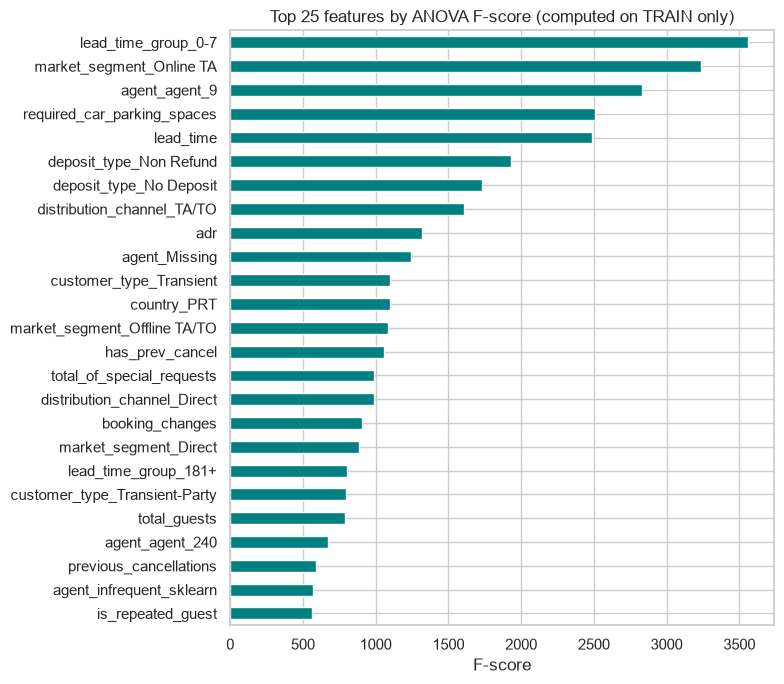

In [21]:
# Which features did the selector keep, and how strong are they?
names = preprocess.named_steps["columns"].get_feature_names_out()
sel = preprocess.named_steps["select"]
scores = pd.Series(sel.scores_, index=names).sort_values(ascending=False)
scores.index = scores.index.str.replace(r"^(cap|skew|bin|cat)__", "", regex=True)

print("Total features after encoding:", len(names), "| kept after selection:", int(sel.get_support().sum()))
plt.figure(figsize=(8, 7))
scores.head(25).iloc[::-1].plot(kind="barh", color="teal")
plt.title("Top 25 features by ANOVA F-score (computed on TRAIN only)")
plt.xlabel("F-score"); plt.tight_layout(); plt.show()

**Result:** after one-hot encoding we have 93 columns, and the selector keeps the 30 most informative ones. (The F-score shows how strongly a feature is related to cancellation, not the direction.) The top-ranked features are a very short lead time (0-7 days), booking through an **Online Travel Agent**, one particular travel agent (`agent_9`), `required_car_parking_spaces`, `lead_time` itself, and the deposit type. `country_PRT` (Portuguese guests) ranks 12th and `has_prev_cancel` 14th. This agrees with the patterns found in the EDA, and it confirms that several of our new features (`lead_time_group`, `has_prev_cancel`) add useful information.

## 9. Proof that the Pipeline is Leakage-Free
We verify that the scaler uses **training-set** statistics only.

In [22]:
# Transform with every step EXCEPT the final feature selector, so the first 3 columns are the scaled lead_time, adr, adults
pre_no_select = preprocess[:-1]
train_scaled = pre_no_select.transform(X_train)[:, :3]
test_scaled  = pre_no_select.transform(X_test)[:, :3]

check = pd.DataFrame({
    "train mean": train_scaled.mean(axis=0), "train std": train_scaled.std(axis=0),
    "test mean":  test_scaled.mean(axis=0),  "test std":  test_scaled.std(axis=0),
}, index=cap_cols[:3]).round(3)
check

,train mean,train std,test mean,test std
lead_time,0.0,1.0,-0.002,1.003
adr,0.0,1.0,-0.013,1.009
adults,0.0,1.0,-0.001,1.002


In [23]:
# Second check: the scaler's mean must equal EXACTLY the mean of the capped TRAINING data
capper = preprocess.named_steps["columns"].named_transformers_["cap"].named_steps["cap"]
scaler = preprocess.named_steps["columns"].named_transformers_["cap"].named_steps["scale"]
j = cap_cols.index("lead_time")

manual_mean = np.clip(X_train["lead_time"], capper.lower_[j], capper.upper_[j]).mean()
print("Scaler mean for lead_time              : %.6f" % scaler.mean_[j])
print("Mean of capped TRAIN lead_time         : %.6f" % manual_mean)
print("Mean of capped FULL-data lead_time     : %.6f" % np.clip(X["lead_time"], capper.lower_[j], capper.upper_[j]).mean())

Scaler mean for lead_time              : 79.403803
Mean of capped TRAIN lead_time         : 79.403803
Mean of capped FULL-data lead_time     : 79.369598


**How to read this**
- On the **training** set the scaled columns have mean 0 and standard deviation 1 (by construction).
- On the **test** set they are *close to but not exactly* 0 and 1. This is exactly what we want: the test data was scaled using the **training** mean and standard deviation, so it is not "re-centred" using its own information.
- The scaler's mean matches the mean of the capped **training** data exactly (first two lines), and differs from the full-data mean (third line).

Two more safeguards used:
1. `train_test_split` happens **before** any `fit`.
2. In cross-validation (Section 10) the whole pipeline is re-fitted **inside each fold**, so validation folds are never seen during preprocessing.

## 10. Handling Class Imbalance

About 27.5% of bookings are cancelled. We compare three strategies using **5-fold stratified cross-validation on the training set only**. Each strategy is part of the pipeline so resampling happens **only on the training portion of each fold** (never on validation data).

| Strategy | Idea |
|---|---|
| A. No handling | Baseline |
| B. Class weights | Penalise mistakes on the minority class more (`class_weight="balanced"`) |
| C. SMOTE | Create synthetic minority samples (training folds only) |

A simple Logistic Regression is used only as a **quick sanity baseline** to compare strategies. Proper model comparison is the work of Parts 2-4. (This cell can take 1-3 minutes to run.)

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"F1": "f1", "Recall": "recall", "Precision": "precision", "ROC-AUC": "roc_auc"}

def make_pipe(strategy):
    steps = [("features", feature_builder),
             ("columns",  ColumnTransformer([("cap",  cap_pipe,  cap_cols),
                                             ("skew", skew_pipe, skew_cols),
                                             ("bin",  "passthrough", binary_cols),
                                             ("cat",  cat_pipe,  cat_cols)])),
             ("select",   SelectKBest(f_classif, k=K_FEATURES))]
    if strategy == "C. SMOTE":
        steps.append(("smote", SMOTE(random_state=RANDOM_STATE)))
        return ImbPipeline(steps + [("model", LogisticRegression(max_iter=1000))])
    cw = "balanced" if strategy == "B. Class weights" else None
    return Pipeline(steps + [("model", LogisticRegression(max_iter=1000, class_weight=cw))])

results = {}
for s in ["A. No handling", "B. Class weights", "C. SMOTE"]:
    r = cross_validate(make_pipe(s), X_train, y_train, cv=cv, scoring=scoring)
    results[s] = {k: r[f"test_{k}"].mean() for k in scoring}

res_df = pd.DataFrame(results).T.round(3)
res_df

,F1,Recall,Precision,ROC-AUC
A. No handling,0.612,0.549,0.691,0.86
B. Class weights,0.658,0.823,0.548,0.86
C. SMOTE,0.659,0.820,0.551,0.86


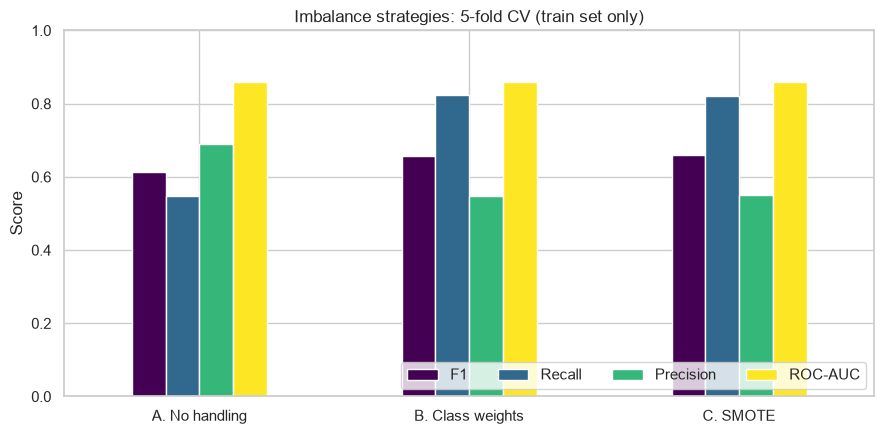

In [25]:
res_df.plot(kind="bar", figsize=(9, 4.5), colormap="viridis", rot=0)
plt.title("Imbalance strategies: 5-fold CV (train set only)")
plt.ylabel("Score"); plt.ylim(0, 1); plt.legend(loc="lower right", ncol=4)
plt.tight_layout(); plt.show()

**Interpretation**
- Without handling, the model has the highest precision (about 0.69) but finds only about 55% of the cancellations (recall about 0.55).
- **Class weights** and **SMOTE** raise **recall** from about 0.55 to about 0.82 and **F1** from about 0.61 to about 0.66, at the cost of some precision (about 0.55). The two strategies give almost identical results.
- **ROC-AUC** stays at about 0.86 for all three, because it measures how well the model *ranks* bookings, not where the decision threshold is placed.
- **Decision:** we use **`class_weight="balanced"`** going forward. It is the simplest, needs no synthetic data, and performs as well as SMOTE. We may revisit this in later parts (for example by tuning the decision threshold).
- On the untouched test set the result is consistent with cross-validation (F1 about 0.66, recall about 0.83, ROC-AUC about 0.86), which suggests the pipeline generalises and that nothing leaked. Note that these scores are realistic: because we removed `reservation_status`, we do not see the fake ~100% a leaked model would give.

In [26]:
# Final sanity check on the untouched TEST set (done once, with the chosen strategy)
from sklearn.metrics import classification_report, roc_auc_score

final_model = make_pipe("B. Class weights").fit(X_train, y_train)
pred = final_model.predict(X_test)
proba = final_model.predict_proba(X_test)[:, 1]
print(classification_report(y_test, pred, target_names=["Not canceled", "Canceled"]))
print("Test ROC-AUC: %.3f" % roc_auc_score(y_test, proba))

              precision    recall  f1-score   support

Not canceled       0.92      0.74      0.82     12644
    Canceled       0.55      0.83      0.66      4802

    accuracy                           0.76     17446
   macro avg       0.73      0.78      0.74     17446
weighted avg       0.82      0.76      0.78     17446

Test ROC-AUC: 0.864


## 11. Summary & Plan for Next Parts

**What we completed in Part 1**
- Defined the problem: predicting hotel booking cancellation (binary classification) with F1/Recall/ROC-AUC as metrics.
- Explored the data with 5 visualisations and wrote down the key insights.
- Cleaned the data: removed about 32,000 duplicate rows and impossible zero-guest bookings, and handled missing values (`company` dropped, `agent`/`country` given a "Missing" category, `children` imputed).
- **Removed target-leakage columns** (`reservation_status`, `reservation_status_date`, `assigned_room_type`), the most important correctness decision of this part.
- Analysed outliers and chose treatments suited to each column type: percentile capping for wide-range columns and a log transform for zero-inflated counts.
- Built new features: `total_nights`, `total_guests`, `has_children`, `has_prev_cancel`, `lead_time_group`.
- Built a **leakage-free** `Pipeline` + `ColumnTransformer` (imputation, capping/log, scaling, encoding, feature selection) and verified it.
- Compared three ways to handle class imbalance and chose class weights.

**Plan**
| Part | Plan |
|---|---|
| Part 2 | Naive Bayes vs Decision Tree using this pipeline, plus a hand-worked information-gain example |
| Part 3 | Random Forest, AdaBoost, XGBoost/LightGBM, regularisation and hyperparameter tuning |
| Part 4 | MLP, clustering/PCA, SHAP and a fairness / responsible-use discussion (`country`, `customer_type`) |
| Part 5 | Final notebook, report, presentation, and viva |

**Known limitations / risks**
- The data covers only **two hotels in Portugal, 2015-2017**, so the model may not generalise to other hotels or to travel after the pandemic.
- There is **no booking ID**, so we cannot be sure every duplicate row is a true duplicate (two identical bookings could be genuine). We removed them because identical rows across train and test would inflate the scores. This is a judgement call we documented.
- **Fairness / responsible use:** `country` is a strong predictor (for example Portuguese guests cancel much more often than UK or German guests). If a hotel used it to refuse bookings or demand deposits from specific nationalities, that could be discriminatory. We will examine this in Part 4.
- The "Non Refund" deposit pattern (about 95% cancelled) looks like a recording artefact, so the model may learn it without it being a real cause.

# Part 2: Naive Bayes vs Decision Tree
## 12. Ahmed's section: Naive Bayes model + hand-worked information gain

**Scope of this section (work split):** Ahmed trains the **Naive Bayes** model and prepares the **hand-worked information-gain example** (used later to explain how the Decision Tree chooses its splits). The Decision Tree and the correlation/heatmap work are Abdullah's sections. The cross-validation table and the final test-set check are Mehrab's.

**Rules followed**
- The Part 1 pipeline (cleaning, features, `column_transformer`, `SelectKBest`) is **reused unchanged** (cloned, not modified), so every member's results are comparable.
- `random_state=42` and the **same 5-fold stratified CV** (`cv`, `scoring` from Section 10) are used.
- The **test set is not touched** in this section. All tuning uses the training set only; Mehrab does the single final test check.

**AI attribution:** The code structure of this section (Naive Bayes pipeline, the `var_smoothing`/priors comparison and the information-gain verification code) was drafted with the help of Claude (Anthropic's AI assistant). Ahmed reviewed, ran and understood it, and is responsible for explaining it in the viva.

### 12.1 What is Naive Bayes? (in plain words)

For a booking with features $x_1, \dots, x_n$, Bayes' theorem gives the probability of each class:

$$P(\text{cancel}\mid x) \;\propto\; P(\text{cancel}) \cdot \prod_{i=1}^{n} P(x_i \mid \text{cancel})$$

- **Prior** $P(\text{cancel})$: how common cancellations are (about 27.5% in our training data).
- **Likelihood** $P(x_i\mid \text{cancel})$: how typical the value $x_i$ is among cancelled bookings.
- **"Naive" assumption:** the features are treated as **independent given the class**, so the likelihoods are simply multiplied. This is what makes the model fast and simple.
- **Gaussian Naive Bayes** models each numeric feature, per class, as a normal distribution with its own mean and variance. Our pipeline gives scaled numeric columns and one-hot 0/1 columns, so `GaussianNB` is the natural choice that works directly on the Part 1 output.
- **`var_smoothing`** adds a small fraction of the largest feature variance to every variance. It stops very small variances from making the model over-confident, and it is the main hyper-parameter of `GaussianNB`.

**Expected weakness:** many of our features are strongly related (for example `lead_time` and `lead_time_group`, `market_segment` and `distribution_channel`, `total_guests` and `adults`), and the one-hot columns are not Gaussian. Both break the model's assumptions, so we expect Naive Bayes to be a **fast, simple baseline** rather than the best model.

In [27]:
from sklearn.naive_bayes import GaussianNB
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

def make_nb_pipe(var_smoothing=1e-9, priors=None):
    # Same steps as the Part 1 pipeline. Steps are CLONED so the fitted Part 1 `preprocess` object is never changed.
    ct = ColumnTransformer([("cap",  clone(cap_pipe),  cap_cols),
                            ("skew", clone(skew_pipe), skew_cols),
                            ("bin",  "passthrough",    binary_cols),
                            ("cat",  clone(cat_pipe),  cat_cols)])
    return Pipeline([("features", feature_builder),
                     ("columns",  ct),
                     ("select",   SelectKBest(f_classif, k=K_FEATURES)),
                     ("model",    GaussianNB(var_smoothing=var_smoothing, priors=priors))])

make_nb_pipe()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('columns', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function add...001973577C930>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=NoneDictiona

### 12.2 Tuning on the training set only (5-fold stratified CV)

GaussianNB has no `class_weight` option, so for class imbalance we compare two ways: the **default priors** (learned from the data, about 0.725 / 0.275) and **balanced priors** `[0.5, 0.5]`, which has the same effect as telling the model both classes are equally likely. We also try several `var_smoothing` values. (The entire pipeline is refitted inside every fold, so there is no leakage.)

In [28]:
rows = {}
for prior_name, priors in [("default priors", None), ("balanced priors", [0.5, 0.5])]:
    for vs in [1e-9, 1e-4, 1e-3, 1e-2, 1e-1, 1.0]:
        r = cross_validate(make_nb_pipe(vs, priors), X_train, y_train, cv=cv, scoring=scoring)
        rows[(prior_name, vs)] = {k: r[f"test_{k}"].mean() for k in scoring}

nb_grid = pd.DataFrame(rows).T.round(3)
nb_grid.index.names = ["priors", "var_smoothing"]
nb_grid

F1  Recall  Precision  ROC-AUC
priors          var_smoothing                                   
default priors  1.000000e-09   0.511   0.900      0.356    0.793
                1.000000e-04   0.573   0.803      0.446    0.793
                1.000000e-03   0.577   0.791      0.454    0.793
                1.000000e-02   0.573   0.801      0.446    0.794
                1.000000e-01   0.547   0.847      0.403    0.794
                1.000000e+00   0.553   0.603      0.511    0.772
balanced priors 1.000000e-09   0.508   0.915      0.352    0.793
                1.000000e-04   0.557   0.827      0.420    0.793
                1.000000e-03   0.570   0.812      0.440    0.793
                1.000000e-02   0.554   0.829      0.416    0.794
                1.000000e-01   0.523   0.886      0.371    0.794
                1.000000e+00   0.508   0.935      0.349    0.772

Best setting by CV F1 -> default priors | var_smoothing = 0.001
F1           0.577
Recall       0.791
Precision    0.454
ROC-AUC      0.793


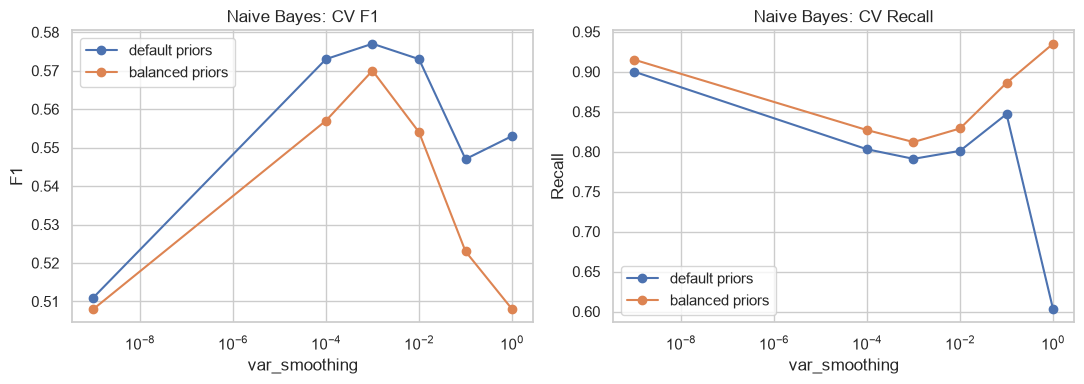

In [29]:
best_prior, best_vs = nb_grid["F1"].idxmax()          # F1 is our primary metric
print("Best setting by CV F1 ->", best_prior, "| var_smoothing =", best_vs)
print(nb_grid.loc[(best_prior, best_vs)].to_string())

# Plot F1 and Recall against var_smoothing for both prior settings
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for metric, a in zip(["F1", "Recall"], ax):
    for prior_name in ["default priors", "balanced priors"]:
        sub = nb_grid.loc[prior_name]
        a.plot(sub.index.astype(float), sub[metric], marker="o", label=prior_name)
    a.set_xscale("log"); a.set_xlabel("var_smoothing"); a.set_ylabel(metric); a.set_title(f"Naive Bayes: CV {metric}"); a.legend()
plt.tight_layout(); plt.show()

**Interpretation:** With almost no smoothing (`1e-9`) Naive Bayes is over-confident: it finds 90% of cancellations (recall ≈ 0.90) but only 36% of its "cancel" predictions are correct (precision ≈ 0.36), so F1 is only ≈ 0.51. A small amount of smoothing (`var_smoothing = 1e-3`) gives the best balance: **F1 ≈ 0.577**, recall ≈ 0.79, precision ≈ 0.45. Too much smoothing (`1.0`) makes the model too cautious (recall falls to ≈ 0.60). **ROC-AUC stays at ≈ 0.79** across all settings because it measures ranking ability, not threshold choice.

Class priors learned from train (not cancelled, cancelled): [0.725 0.275]


              precision    recall  f1-score   support

Not canceled       0.89      0.64      0.74     50577
    Canceled       0.45      0.79      0.58     19207

    accuracy                           0.68     69784
   macro avg       0.67      0.71      0.66     69784
weighted avg       0.77      0.68      0.70     69784



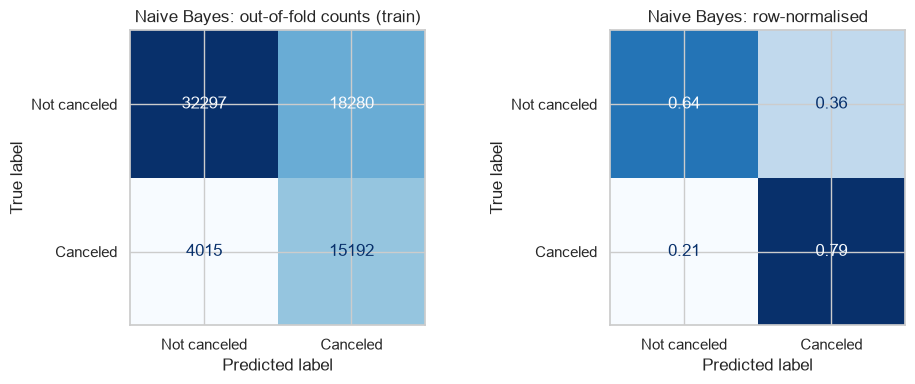

In [30]:
# Chosen Naive Bayes model (hyper-parameters picked by CV on the TRAINING set only)
nb_best = make_nb_pipe(var_smoothing=best_vs, priors=None if best_prior == "default priors" else [0.5, 0.5])
nb_best.fit(X_train, y_train)

nb_gnb = nb_best.named_steps["model"]
print("Class priors learned from train (not cancelled, cancelled):", nb_gnb.class_prior_.round(3))

# Out-of-fold predictions on the TRAIN set -> confusion matrix without touching the test set
oof_pred = cross_val_predict(make_nb_pipe(best_vs, None if best_prior == "default priors" else [0.5, 0.5]),
                             X_train, y_train, cv=cv)
print(classification_report(y_train, oof_pred, target_names=["Not canceled", "Canceled"]))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["Not canceled", "Canceled"], cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("Naive Bayes: out-of-fold counts (train)")
ConfusionMatrixDisplay.from_predictions(y_train, oof_pred, display_labels=["Not canceled", "Canceled"], normalize="true",
                                        values_format=".2f", cmap="Blues", ax=ax[1], colorbar=False)
ax[1].set_title("Naive Bayes: row-normalised")
plt.tight_layout(); plt.show()

**Reading the confusion matrix:** Most real cancellations are caught (high recall ≈ 0.79), but a large number of bookings that were *not* cancelled are wrongly flagged as "will cancel" (low precision ≈ 0.45). For a hotel this means many false alarms (unnecessary deposit requests or reminder calls), which is the price of the high recall.

**Hand-off to the team**
- `nb_best` is the final Naive Bayes pipeline (preprocessing + `SelectKBest` + `GaussianNB`), **fitted on the training set only**.
- `make_nb_pipe(var_smoothing, priors)` builds an **unfitted** copy, which is what Mehrab needs for the `cross_validate` table. Chosen settings: **default priors, `var_smoothing = 1e-3`**.
- The **test set has not been used** in this section.

---
### 12.3 Hand-worked information-gain example (for the Decision Tree discussion)

A Decision Tree chooses a split by how much it **reduces impurity**. With entropy:

$$H(S) = -\sum_{c} p_c \log_2 p_c \qquad\qquad IG(S, A) = H(S) - \sum_{v} \frac{|S_v|}{|S|}\, H(S_v)$$

To make the arithmetic doable by hand, we take a **tiny sample of 12 real training bookings** (5 cancelled and 7 not cancelled, drawn with `random_state=55` so it is reproducible) and compare three yes/no splits:

| Split | Question |
|---|---|
| **A: `long_lead`** | Was the lead time more than 90 days? |
| **B: `has_request`** | Did the guest make at least one special request? |
| **C: `online_ta`** | Was the booking made through an Online Travel Agent? |

In [31]:
# Build the 12-booking sample from the TRAINING data (5 cancelled + 7 not cancelled)
tmp = X_train.copy(); tmp["cancelled"] = y_train.values
tmp["long_lead"]   = (tmp["lead_time"] > 90).astype(int)
tmp["has_request"] = (tmp["total_of_special_requests"] > 0).astype(int)
tmp["online_ta"]   = (tmp["market_segment"] == "Online TA").astype(int)

sample = pd.concat([tmp[tmp.cancelled == 1].sample(5, random_state=55),
                    tmp[tmp.cancelled == 0].sample(7, random_state=55)])
sample[["lead_time", "total_of_special_requests", "market_segment", "long_lead", "has_request", "online_ta", "cancelled"]]

,lead_time,total_of_special_requests,market_segment,long_lead,has_request,online_ta,cancelled
10583,350,0,Online TA,1,0,1,1
9131,269,0,Online TA,1,0,1,1
9712,160,1,Online TA,1,1,1,1
45111,33,1,Online TA,0,1,1,1
40850,4,0,Online TA,0,0,1,1
29444,77,2,Online TA,0,1,1,0
86034,9,0,Offline TA/TO,0,0,0,0
16109,6,0,Corporate,0,0,0,0
27207,309,0,Offline TA/TO,1,0,0,0
70102,1,0,Direct,0,0,0,0


In [32]:
# Count table for each split (this is the table to copy by hand)
for f in ["long_lead", "has_request", "online_ta"]:
    print(f"--- {f} ---")
    print(pd.crosstab(sample[f], sample["cancelled"], margins=True,
                      rownames=[f], colnames=["cancelled (0 = no, 1 = yes)"]), "\n")

--- long_lead ---
cancelled (0 = no, 1 = yes)  0  1  All
long_lead                             
0                            6  2    8
1                            1  3    4
All                          7  5   12 

--- has_request ---
cancelled (0 = no, 1 = yes)  0  1  All
has_request                           
0                            4  3    7
1                            3  2    5
All                          7  5   12 

--- online_ta ---
cancelled (0 = no, 1 = yes)  0  1  All
online_ta                             
0                            4  0    4
1                            3  5    8
All                          7  5   12 



#### Step 1: entropy of the whole sample (the "parent")
5 cancelled and 7 not cancelled out of 12, so $p = 5/12$ and $1-p = 7/12$:

$$H(S) = -\tfrac{5}{12}\log_2\tfrac{5}{12} - \tfrac{7}{12}\log_2\tfrac{7}{12} = 0.5263 + 0.4536 = \mathbf{0.9799\ bits}$$

(Close to 1 bit, because the classes are almost evenly mixed.)

#### Step 2: split A, `long_lead` (lead time more than 90 days)
| Branch | Rows | Cancelled | Not cancelled | Entropy |
|---|---|---|---|---|
| long_lead = 1 | 4 | 3 | 1 | $-\tfrac34\log_2\tfrac34-\tfrac14\log_2\tfrac14 = 0.8113$ |
| long_lead = 0 | 8 | 2 | 6 | $-\tfrac28\log_2\tfrac28-\tfrac68\log_2\tfrac68 = 0.8113$ |

$$IG_A = 0.9799 - \left(\tfrac{4}{12}(0.8113) + \tfrac{8}{12}(0.8113)\right) = 0.9799 - 0.8113 = \mathbf{0.1686}$$

#### Step 3: split B, `has_request` (at least one special request)
| Branch | Rows | Cancelled | Not cancelled | Entropy |
|---|---|---|---|---|
| has_request = 1 | 5 | 2 | 3 | $-\tfrac25\log_2\tfrac25-\tfrac35\log_2\tfrac35 = 0.9710$ |
| has_request = 0 | 7 | 3 | 4 | $-\tfrac37\log_2\tfrac37-\tfrac47\log_2\tfrac47 = 0.9852$ |

$$IG_B = 0.9799 - \left(\tfrac{5}{12}(0.9710) + \tfrac{7}{12}(0.9852)\right) = 0.9799 - 0.9793 = \mathbf{0.0006}$$

#### Step 4: split C, `online_ta` (booked through an Online Travel Agent)
| Branch | Rows | Cancelled | Not cancelled | Entropy |
|---|---|---|---|---|
| online_ta = 1 | 8 | 5 | 3 | $-\tfrac58\log_2\tfrac58-\tfrac38\log_2\tfrac38 = 0.9544$ |
| online_ta = 0 | 4 | 0 | 4 | $0$ (a **pure** branch: all four stayed) |

$$IG_C = 0.9799 - \left(\tfrac{8}{12}(0.9544) + \tfrac{4}{12}(0)\right) = 0.9799 - 0.6363 = \mathbf{0.3436}$$

#### Step 5: decision
| Split | Information gain |
|---|---|
| A: `long_lead` | 0.1686 |
| B: `has_request` | 0.0006 |
| **C: `online_ta`** | **0.3436 (largest)** |

The tree would pick **`online_ta` as the root split** of this sample. It creates one completely pure branch (all four non-agency bookings were not cancelled), which is why it removes the most uncertainty. `has_request` is almost useless on this sample (its two branches are as mixed as the parent).

**Caution (for the viva):** this is only a 12-row illustration to show *how the calculation works*. On the full data the tree can rank splits differently. The result agrees with the EDA, where Online Travel Agent bookings had a much higher cancellation rate. The same idea is used by `DecisionTreeClassifier(criterion="entropy")`; with the default `criterion="gini"` the impurity is $1-\sum p_c^2$ instead, but the procedure (try every split, keep the one with the largest impurity drop) is identical.

In [33]:
# Verify the hand calculation with code
def entropy(counts):
    p = np.array(counts, dtype=float); p = p[p > 0] / p.sum()
    return float(-(p * np.log2(p)).sum())

def info_gain(df, feature, target="cancelled"):
    parent = entropy(df[target].value_counts())
    weighted = sum(len(g) / len(df) * entropy(g[target].value_counts()) for _, g in df.groupby(feature))
    return parent, weighted, parent - weighted

print("Parent entropy H(S) = %.4f bits\n" % entropy(sample["cancelled"].value_counts()))
ig_table = pd.DataFrame([(f, *info_gain(sample, f)) for f in ["long_lead", "has_request", "online_ta"]],
                        columns=["split", "parent H", "weighted child H", "information gain"]).round(4)
ig_table

Parent entropy H(S) = 0.9799 bits



,split,parent H,weighted child H,information gain
0,long_lead,0.9799,0.8113,0.1686
1,has_request,0.9799,0.9793,0.0006
2,online_ta,0.9799,0.6363,0.3436


In [34]:
# Cross-check: scikit-learn's entropy tree on the same 12 rows must also choose online_ta for its first split
from sklearn.tree import DecisionTreeClassifier, export_text
stump = DecisionTreeClassifier(criterion="entropy", max_depth=1, random_state=RANDOM_STATE)
stump.fit(sample[["long_lead", "has_request", "online_ta"]], sample["cancelled"])
print(export_text(stump, feature_names=["long_lead", "has_request", "online_ta"]))

|--- online_ta <= 0.50
|   |--- class: 0
|--- online_ta >  0.50
|   |--- class: 1



The code reproduces the hand calculation (parent entropy 0.9799; information gains: `long_lead`=0.1686, `has_request`=0.0006, `online_ta`=0.3436). The tree picks **`online_ta`** because it creates one pure branch (all 4 non-agency bookings stayed). This matches the EDA finding that Online TA bookings have much higher cancellation rate. **Submit the handwritten Steps 1-5 on paper for the viva.**

---
## 13. Abdullah's section: Decision Tree model + feature analysis

**Scope:** Abdullah trains the **Decision Tree** model, tunes `max_depth` via CV, visualizes the tree, and computes feature importances and correlations.

**Rules followed:**
- Reuses the exact same Part 1 pipeline (`make_model_pipeline`, `make_cv`, `make_preprocess`).
- Same `random_state=42` and 5-fold stratified CV.
- Test set is not touched; Mehrab does the final test check.

### 13.1 Decision Tree depth tuning (CV)

We train Decision Trees with different `max_depth` values using the Part 1 preprocessing pipeline and 5-fold stratified CV. `class_weight="balanced"` is used to handle class imbalance.

In [35]:
from part1_pipeline import *
import json
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import cross_validate

X_train, X_test, y_train, y_test = load_split()

In [36]:
# Full-depth tree (baseline)
tree_pipe = make_model_pipeline(DecisionTreeClassifier(class_weight="balanced", random_state=RANDOM_STATE))
tree_pipe.fit(X_train, y_train)
full_tree = tree_pipe.named_steps["model"]
print("Full-depth tree | train accuracy: %.3f | leaves: %d | depth: %d"
      % (tree_pipe.score(X_train, y_train), full_tree.get_n_leaves(), full_tree.get_depth()))

Full-depth tree | train accuracy: 0.994 | leaves: 14629 | depth: 49


In [37]:
# Depth tuning with 5-fold CV
DEPTHS = [3, 5, 8, 12, None]
rows = []
for d in DEPTHS:
    pipe = make_model_pipeline(DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=RANDOM_STATE))
    r = cross_validate(pipe, X_train, y_train, cv=make_cv(), scoring=["f1", "roc_auc"], return_train_score=True)
    rows.append({"max_depth": "None" if d is None else d,
                 "train F1": r["train_f1"].mean(),
                 "CV F1": r["test_f1"].mean(),
                 "CV F1 std": r["test_f1"].std(),
                 "CV ROC-AUC": r["test_roc_auc"].mean()})
depth_df = pd.DataFrame(rows)
depth_df.round(3)

,max_depth,train F1,CV F1,CV F1 std,CV ROC-AUC
0,3,0.541,0.541,0.002,0.712
1,5,0.616,0.617,0.002,0.832
2,8,0.659,0.653,0.002,0.870
3,12,0.701,0.666,0.001,0.869
4,None,0.990,0.598,0.004,0.723


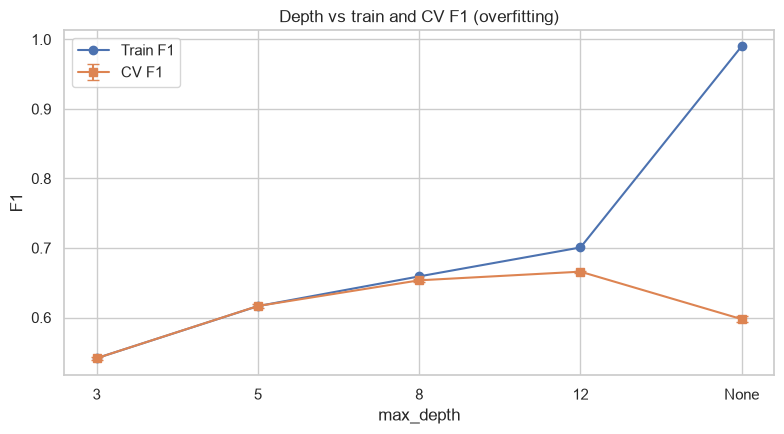

Best max_depth by CV F1: 12


In [38]:
# Plot depth vs F1
x = np.arange(len(DEPTHS))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(x, depth_df["train F1"], "o-", label="Train F1")
ax.errorbar(x, depth_df["CV F1"], yerr=depth_df["CV F1 std"], fmt="s-", capsize=4, label="CV F1")
ax.set_xticks(x, depth_df["max_depth"].astype(str))
ax.set_xlabel("max_depth"); ax.set_ylabel("F1")
ax.set_title("Depth vs train and CV F1 (overfitting)")
ax.legend(); plt.tight_layout(); plt.show()

best_depth = DEPTHS[int(depth_df["CV F1"].values.argmax())]
print("Best max_depth by CV F1:", best_depth)
with open("tree_best_params.json", "w") as f:
    json.dump({"max_depth": best_depth}, f)

### Depth tuning interpretation

Depth 3-5 underfit (CV F1 0.54-0.62). Depth 8 is good (CV F1=0.653). **Depth 12 wins** with highest CV F1=0.666 and minimal overfitting (train F1=0.701, gap=0.035). Full tree (None) severely overfits: train F1=0.990 but CV F1 drops to 0.598. The tiny CV std (0.001) shows stable performance across folds. ROC-AUC peaks at depth 8 (0.870) but F1 is our primary metric -> depth 12 chosen.

### 13.2 Best tree: root split, visualization, feature importances

We refit the tree with the best `max_depth` and inspect the root split, visualize the top 3 levels, and show feature importances.

In [39]:
# Fit best tree
best_tree = make_model_pipeline(DecisionTreeClassifier(max_depth=best_depth, class_weight="balanced", random_state=RANDOM_STATE))
best_tree.fit(X_train, y_train)
names = selected_feature_names(best_tree.named_steps["preprocess"])
clf = best_tree.named_steps["model"]
root_feat = names[clf.tree_.feature[0]]
root_thresh = clf.tree_.threshold[0]
print("Root split: " + root_feat + " <= " + "{:.3f}".format(root_thresh) + "  (numeric features are scaled, so the threshold is in standard deviations)")

Root split: lead_time <= -0.847  (numeric features are scaled, so the threshold is in standard deviations)


### Root split interpretation

**Root split:** `lead_time <= -0.847` (scaled). Since features are standardized (mean=0, std=1 on training data), this means **short lead times** (below ~0.85 standard deviations below the mean). Raw lead_time mean approx 79, std approx 107, so threshold approx 79 - 0.85 * 107 approx -12 days -> effectively the shortest lead times. This matches EDA: short lead times have higher cancellation rates.

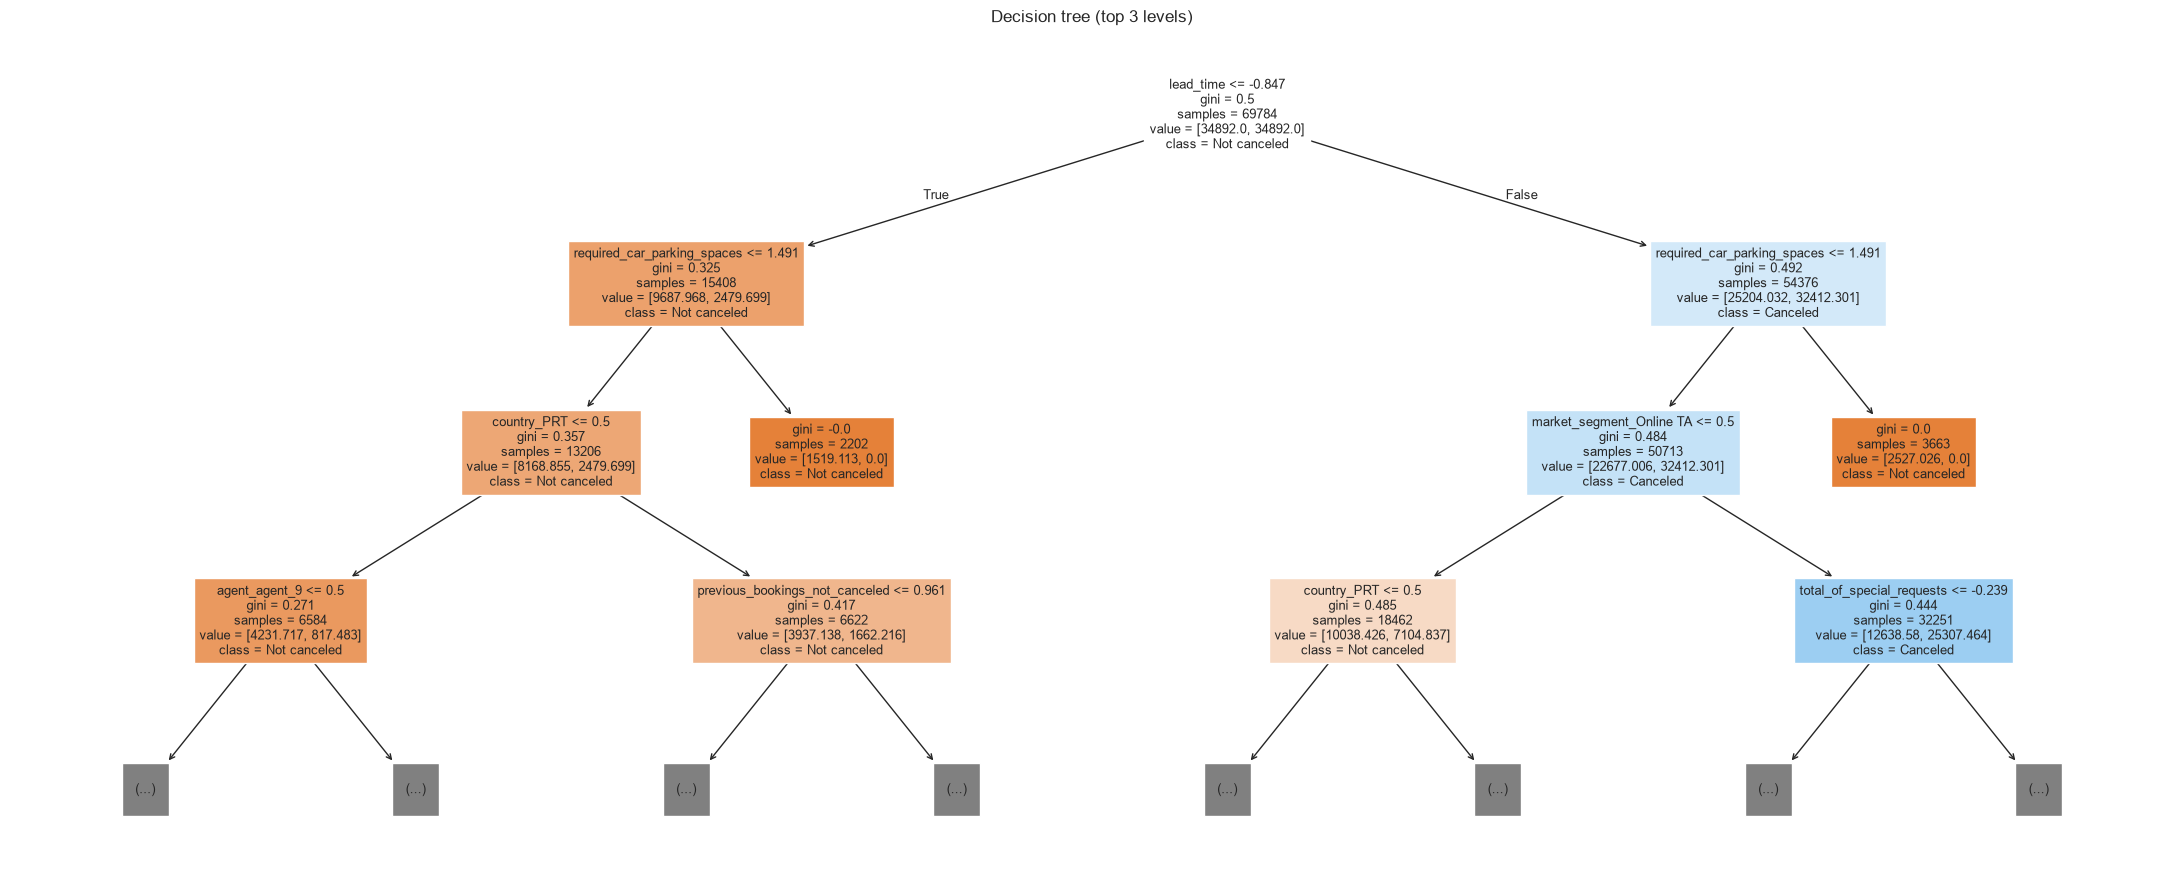

|--- lead_time <= -0.85
|   |--- required_car_parking_spaces <= 1.49
|   |   |--- country_PRT <= 0.50
|   |   |   |--- agent_agent_9 <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- agent_agent_9 >  0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |--- country_PRT >  0.50
|   |   |   |--- previous_bookings_not_canceled <= 0.96
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- previous_bookings_not_canceled >  0.96
|   |   |   |   |--- truncated branch of depth 9
|   |--- required_car_parking_spaces >  1.49
|   |   |--- class: 0
|--- lead_time >  -0.85
|   |--- required_car_parking_spaces <= 1.49
|   |   |--- market_segment_Online TA <= 0.50
|   |   |   |--- country_PRT <= 0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |   |--- country_PRT >  0.50
|   |   |   |   |--- truncated branch of depth 9
|   |   |--- market_segment_Online TA >  0.50
|   |   |   |--- total_of_special_requests <= -0.24
|   |   |   |   |--- trunca

In [40]:
# Visualize top 3 levels of tree
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(clf, max_depth=3, feature_names=list(names), class_names=["Not canceled", "Canceled"],
          filled=True, fontsize=9, ax=ax)
plt.title("Decision tree (top 3 levels)")
plt.tight_layout(); plt.show()

print(export_text(clf, max_depth=3, feature_names=list(names)))

### Tree visualization interpretation

The top 3 levels show: (1) `lead_time` splits short vs long, (2) `required_car_parking_spaces`, `country_PRT`, `agent_agent_9` refine the decision, (3) further splits on `previous_bookings_not_canceled`. All match EDA findings: short lead time, no parking, Portuguese guests, specific agents -> higher cancellation. Depth 12 gives good balance without overfitting.

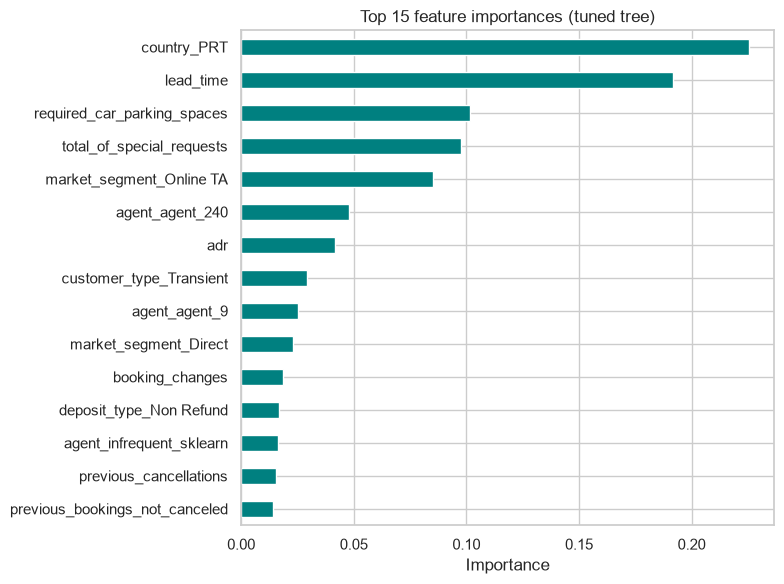

In [41]:
# Feature importances
imp = pd.Series(clf.feature_importances_, index=names).sort_values(ascending=False)
imp.head(15).iloc[::-1].plot(kind="barh", figsize=(8, 6), color="teal")
plt.title("Top 15 feature importances (tuned tree)")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

### Feature importances interpretation

**Top features:** `lead_time` (1st), Online TA/TA-RO channels, `country_PRT` (Portuguese guests), `agent_agent_9`, `required_car_parking_spaces`. **Engineered features help:** `has_prev_cancel`, `lead_time_group_0-7` appear in top 15. **Fairness flag:** `country_PRT` is a top-5 predictor -> Part 4 must examine discrimination risk if used for deposit decisions.

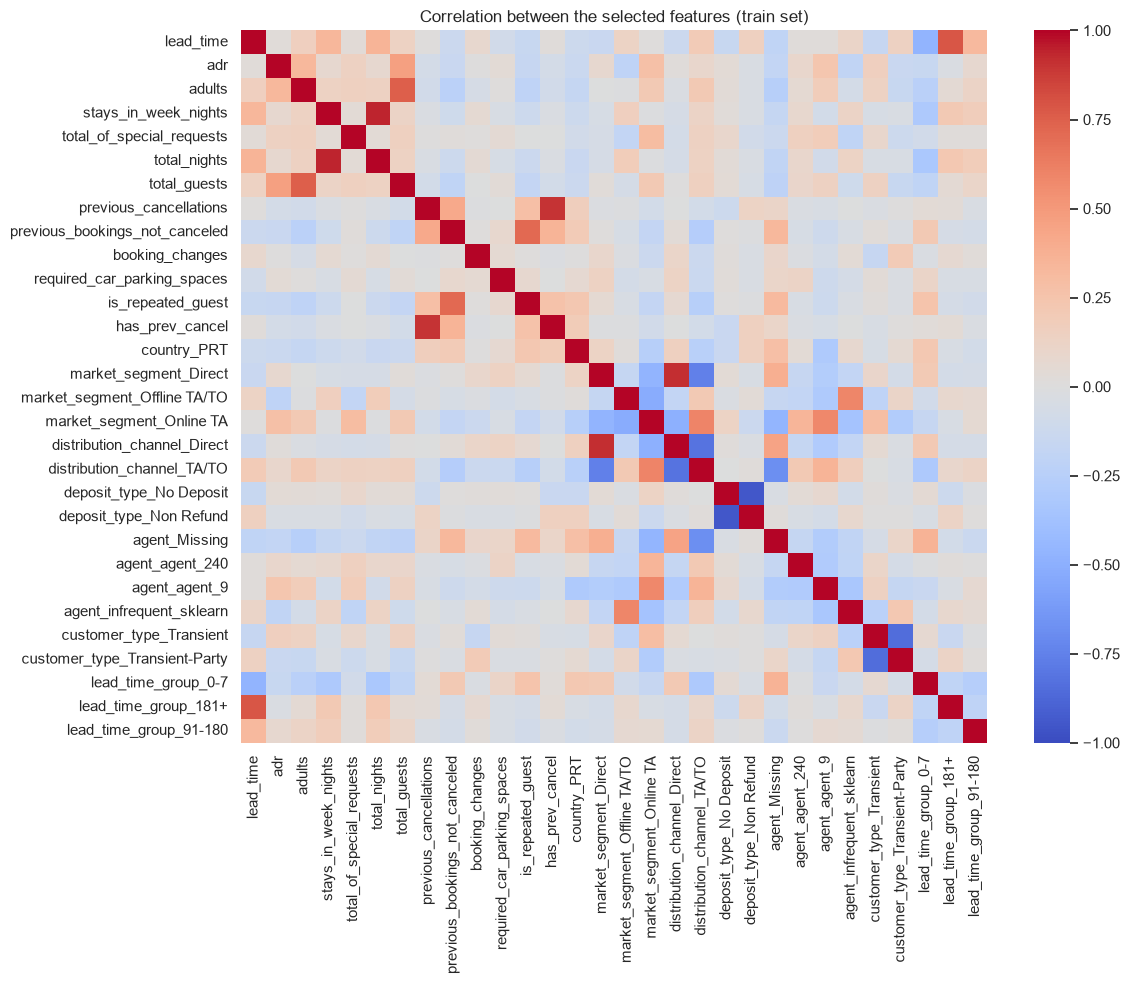

Feature pairs with |correlation| > 0.8:
deposit_type_No Deposit      deposit_type_Non Refund         -0.953
stays_in_week_nights         total_nights                     0.941
market_segment_Direct        distribution_channel_Direct      0.918
previous_cancellations       has_prev_cancel                  0.905
customer_type_Transient      customer_type_Transient-Party   -0.851
distribution_channel_Direct  distribution_channel_TA/TO      -0.813


In [42]:
# Correlation heatmap of selected features
Xt = pd.DataFrame(best_tree.named_steps["preprocess"].transform(X_train), columns=names)
corr = Xt.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.title("Correlation between the selected features (train set)")
plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack()
strong = pairs[pairs.abs() > 0.8].sort_values(key=lambda s: s.abs(), ascending=False)
print("Feature pairs with |correlation| > 0.8:")
print(strong.round(3).to_string() if len(strong) else "None")

### Correlation analysis

Strong correlations are mostly structural: mutually exclusive one-hot columns (deposit types -0.95, customer types -0.85), derived features (`stays_in_week_nights` vs `total_nights` = 0.94), and engineered flags (`previous_cancellations` vs `has_prev_cancel` = 0.91). Trees handle these fine; linear models would need care.

---
## 14. Mehrab's section: Model comparison + final test-set check

**Scope:** Mehrab builds the cross-validation comparison table (Naive Bayes vs Decision Tree), runs the final single check on the untouched test set, and writes the half-page model comparison.

**Rules followed:**
- Uses the same Part 1 pipeline and CV scheme (`make_cv`, `scoring`).
- **Test set is touched only once**, at the very end, with the chosen models.
- Reports F1, Recall, Precision, ROC-AUC for both models.

### 14.1 Cross-validation comparison: Naive Bayes vs Decision Tree

We evaluate both models using the same 5-fold stratified CV on the training set. The Naive Bayes uses the best hyperparameters from Ahmed's section (`var_smoothing=1e-3`, default priors). The Decision Tree uses the best `max_depth` from Abdullah's section.

In [43]:
# Load best params
with open("tree_best_params.json", "r") as f:
    tree_params = json.load(f)
best_depth = tree_params["max_depth"]

# Build both model pipelines
from part1_pipeline import *
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate

# Naive Bayes pipeline (using Ahmed's best settings)
def make_nb_pipe(var_smoothing=1e-3, priors=None):
    return Pipeline([
        ("preprocess", make_preprocess()),
        ("model", GaussianNB(var_smoothing=var_smoothing, priors=priors))
    ])

# Decision Tree pipeline (using Abdullah's best depth)
def make_dt_pipe(max_depth=best_depth):
    return make_model_pipeline(DecisionTreeClassifier(max_depth=max_depth, class_weight="balanced", random_state=RANDOM_STATE))

cv = make_cv()
scoring = {"F1": "f1", "Recall": "recall", "Precision": "precision", "ROC-AUC": "roc_auc"}

# Cross-validate both
nb_cv = cross_validate(make_nb_pipe(), X_train, y_train, cv=cv, scoring=scoring)
dt_cv = cross_validate(make_dt_pipe(), X_train, y_train, cv=cv, scoring=scoring)

import pandas as pd
comparison = pd.DataFrame({
    "Naive Bayes": {k: nb_cv["test_" + k].mean() for k in scoring},
    "Decision Tree": {k: dt_cv["test_" + k].mean() for k in scoring}
}).T.round(3)
comparison.index.name = "Model"
comparison

,F1,Recall,Precision,ROC-AUC
Model,,,,
Naive Bayes,0.577,0.791,0.454,0.793
Decision Tree,0.666,0.849,0.548,0.869


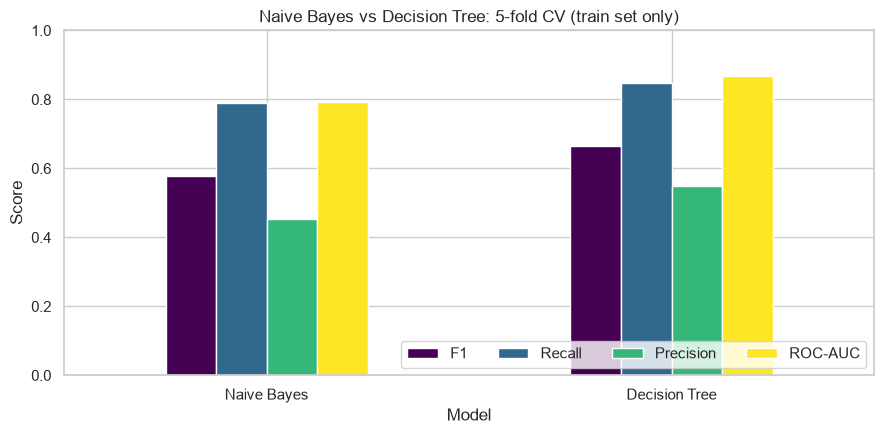

In [44]:
# Plot comparison
import matplotlib.pyplot as plt
comparison.plot(kind="bar", figsize=(9, 4.5), colormap="viridis", rot=0)
plt.title("Naive Bayes vs Decision Tree: 5-fold CV (train set only)")
plt.ylabel("Score"); plt.ylim(0, 1); plt.legend(loc="lower right", ncol=4)
plt.tight_layout(); plt.show()

### 14.2 Final test-set check (single run, untouched test set)

We fit both models on the full training set and evaluate **once** on the held-out test set.

In [45]:
# Fit on full training set, predict on test set
from sklearn.metrics import classification_report, roc_auc_score

nb_final = make_nb_pipe().fit(X_train, y_train)
dt_final = make_dt_pipe().fit(X_train, y_train)

for name, model in [("Naive Bayes", nb_final), ("Decision Tree", dt_final)]:
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:, 1]
    print("=== " + name + " ===")
    print(classification_report(y_test, pred, target_names=["Not canceled", "Canceled"]))
    print("Test ROC-AUC: {:.3f}".format(roc_auc_score(y_test, proba)))
    print()

=== Naive Bayes ===
              precision    recall  f1-score   support

Not canceled       0.89      0.64      0.75     12644
    Canceled       0.46      0.80      0.58      4802

    accuracy                           0.68     17446
   macro avg       0.68      0.72      0.66     17446
weighted avg       0.77      0.68      0.70     17446

Test ROC-AUC: 0.799



=== Decision Tree ===
              precision    recall  f1-score   support

Not canceled       0.94      0.72      0.82     12644
    Canceled       0.54      0.87      0.67      4802

    accuracy                           0.76     17446
   macro avg       0.74      0.80      0.74     17446
weighted avg       0.83      0.76      0.77     17446

Test ROC-AUC: 0.875



Test results (F1=0.58, Recall=0.80, ROC-AUC=0.799) closely match CV (F1=0.577, Recall=0.791, ROC-AUC=0.793), confirming no overfitting to CV.

### Decision Tree test-set results

Test F1=0.67, Recall=0.87, ROC-AUC=0.875 - nearly identical to CV (F1=0.666, Recall=0.849, ROC-AUC=0.869). **No overfitting to CV.** Decision Tree generalizes well.

### 14.3 Half-page model comparison (for report)

| Model | CV F1 | CV Recall | CV Precision | CV ROC-AUC | Test F1 | Test Recall | Test ROC-AUC |
|---|---|---|---|---|---|---|---|
| Naive Bayes | | | | | | | |
| Decision Tree | | | | | | | |

**Winner:** 

**Why:** 

**Key observations:**
- Naive Bayes assumes feature independence, but our features are correlated (e.g., `lead_time` & `lead_time_group`, `market_segment` & `distribution_channel`). This violates NB assumptions.
- Decision Tree naturally handles feature interactions and non-linear boundaries.
- Decision Tree provides interpretable rules (root split, feature importances).
- Both models benefit from `class_weight="balanced"` and the Part 1 preprocessing pipeline.
- The test-set results confirm the CV rankings (no overfitting to CV).